# XYZ GNN Ensemble + Cross-Validation## 目的回应审稿人：单模型不可靠 → 多模型 ensemble 报告均值 ± 标准差## 设计```                     全量数据 (95,152 complexes)                              │                    ┌─────────┼─────────┐                    │         │         │                 训练集 (85%)          测试集 (15%)              ~80,879 complexes     ~14,273 complexes                    │               (固定, 不参与CV)          ┌─────────┼─────────┐          │         │         │       Fold 0    Fold 1    Fold 2      (train 2/3, val 1/3, 各跑3个seed)总计: 3 folds × 3 seeds = 15 个模型测试: 9模型 ensemble 预测 → 均值 ± 标准差```## 模型配置- XYZ GNN: 12头 GAT × 384d × 5层- 23维边特征 (SMILES键 + DFT距离16RBF + Mayer BO)- 自动金属加权- AMP混合精度, CosineWarmRestarts, 早停 patience=40## 预期时间 (5070 Ti)- 每模型 ~35min × 15 = ~9小时

In [1]:
import numpy as np, pandas as pd, time, gzip, os, sys, json
import matplotlib.pyplot as plt, warnings
from collections import Counter
warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

import torch, torch.nn as nn, torch.optim as optim
from torch.amp import autocast, GradScaler

# GPU配置
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.benchmark = True
torch.backends.cuda.enable_flash_sdp(True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory/1024**3:.1f} GB')

from sklearn.metrics import mean_absolute_error, r2_score
from tqdm import tqdm

# ===== 加载目标值 =====
df_y = pd.read_csv('tmQM_y.csv', sep=';')
df_y = df_y.rename(columns={
    'HL_Gap': 'gap', 'HOMO_Energy': 'homo', 'LUMO_Energy': 'lumo',
    'Dipole_M': 'dipole', 'Metal_q': 'metal_charge',
    'Electronic_E': 'E_elec', 'Dispersion_E': 'E_disp',
    'Polarizability': 'polarizability'
})
targets = ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec', 'E_disp', 'polarizability']
print(f'Loaded {len(df_y)} complexes, {len(targets)} targets')



Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti
VRAM: 15.5 GB


Loaded 108541 complexes, 8 targets


In [2]:
print('='*60)
print('Step 1: XYZ+BO解析 + SMILES建图 (全量95k)')
print('='*60)

import gzip
from rdkit import Chem
from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)

def atom_to_z(sym):
    tbl = {"H":1,"He":2,"Li":3,"Be":4,"B":5,"C":6,"N":7,"O":8,"F":9,"Ne":10,
           "Na":11,"Mg":12,"Al":13,"Si":14,"P":15,"S":16,"Cl":17,"Ar":18,
           "K":19,"Ca":20,"Sc":21,"Ti":22,"V":23,"Cr":24,"Mn":25,"Fe":26,
           "Co":27,"Ni":28,"Cu":29,"Zn":30,"Br":35,"Ru":44,"Rh":45,
           "Pd":46,"Ag":47,"Cd":48,"I":53,"Pt":78,"Au":79,"Hg":80,
           "Mo":42,"W":74,"Ir":77,"Os":76,"Re":75}
    return tbl.get(sym, 0)

def is_TM(z):
    return z in [21,22,23,24,25,26,27,28,29,30,39,40,41,42,43,44,45,46,47,48,
                 72,73,74,75,76,77,78,79,80]

def parse_one(xyz_p, bo_p, start_idx=0):
    mols, labels = [], []
    with gzip.open(bo_p, "rt") as f:
        bo_lines = [l.strip() for l in f.readlines()]
    with gzip.open(xyz_p, "rt") as f:
        xyz_blocks = f.read().strip().split(chr(10))
    bo_blocks, cur = [], []
    for line in bo_lines:
        if line.startswith("CSD_code"):
            if cur: bo_blocks.append(cur); cur = []
        elif line: cur.append(line)
    if cur: bo_blocks.append(cur)
    i, mol_idx = 0, start_idx - 1
    while i < len(xyz_blocks):
        line = xyz_blocks[i].strip(); i += 1
        if not line: continue
        parts = line.split()
        if len(parts) == 1 and parts[0].isdigit():
            n_atoms = int(parts[0])
            if i >= len(xyz_blocks): break; i += 1
            atoms, coords = [], []
            for _ in range(n_atoms):
                if i >= len(xyz_blocks): break
                cline = xyz_blocks[i].strip(); i += 1; cparts = cline.split()
                if len(cparts) >= 4:
                    try:
                        z = atom_to_z(cparts[0])
                        coords.append([float(x) for x in cparts[1:4]]); atoms.append(z)
                    except ValueError: continue
            mol_idx += 1
            if not any(is_TM(z) for z in atoms) or len(atoms) <= 1: continue
            bo_mat = None
            if mol_idx < len(bo_blocks):
                bo_mat = np.zeros((n_atoms, n_atoms), dtype=np.float32)
                for bline in bo_blocks[mol_idx]:
                    bparts = bline.split()
                    try: src_idx = int(bparts[0]) - 1
                    except ValueError: continue
                    j = 2
                    while j + 1 < len(bparts):
                        try:
                            nbr = int(bparts[j]) - 1; bo_val = float(bparts[j+1])
                            if 0 <= src_idx < n_atoms and 0 <= nbr < n_atoms:
                                bo_mat[src_idx, nbr] = bo_val
                            j += 3
                        except (ValueError, IndexError): j += 1
            mols.append({"atoms": np.array(atoms), "coords": np.array(coords, dtype=np.float32),
                         "bo": bo_mat, "csv_idx": mol_idx})
            labels.append(df_y.iloc[mol_idx][targets].astype(float).values)
    return mols, labels

all_m, all_l = [], []
for part in [1, 2, 3]:
    print(f'  Part {part}...')
    m, l = parse_one(f"tmQM_X{part}.xyz.gz", f"tmQM_X{part}.BO.gz", start_idx=len(all_m))
    all_m.extend(m); all_l.extend(l)
    print(f'    {len(m)} TM complexes')

print(f'Total: {len(all_m)} TM complexes parsed')

# ===== SMILES建图 (复用tmQM_Fe_XYZ Cell 4) =====
ELEMENT_DATA_SM = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),72:(6,4),73:(6,5),74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}
BOND_TYPES_SM = [1,2,3,12]; B2I_SM = {b:i for i,b in enumerate(BOND_TYPES_SM)}; N_BT_SM = 4
rbf_c = np.linspace(1.0, 5.0, 16); rbf_sigma = 0.2
smiles_by_idx = df_y['SMILES'].tolist()

def atom_features_sm(atom):
    z = atom.GetAtomicNum(); p,g = ELEMENT_DATA_SM.get(z,(0,0))
    return [z, atom.GetDegree(), atom.GetFormalCharge(), p, g,
            int(atom.GetIsAromatic()), atom.GetTotalNumHs(), int(z >= 21)]

def fast_match(sm_atoms, xyz_atoms):
    N = len(sm_atoms)
    if N == len(xyz_atoms) and all(sm_atoms[i] == xyz_atoms[i] for i in range(N)):
        return list(range(N))
    sm_to_xyz = [-1] * N; used = set()
    for i, z_sm in enumerate(sm_atoms):
        for j, z_xyz in enumerate(xyz_atoms):
            if z_sm == z_xyz and j not in used:
                sm_to_xyz[i] = j; used.add(j); break
    return sm_to_xyz

print(f'Building graphs...')
graphs, y_vals, atoms_filt, failed = [], [], [], 0
for idx, m in enumerate(tqdm(all_m, desc='Graphs')):
    csv_i = m["csv_idx"]; smi = smiles_by_idx[csv_i] if csv_i < len(smiles_by_idx) else ''
    if not isinstance(smi, str) or smi == '': failed += 1; continue
    mol = Chem.MolFromSmiles(smi)
    if mol is None: failed += 1; continue
    N = mol.GetNumAtoms()
    sm_atoms = [a.GetAtomicNum() for a in mol.GetAtoms()]
    sm_to_xyz = fast_match(sm_atoms, m['atoms'])
    coords = m['coords']; bo_mat = m.get('bo')

    xf = [atom_features_sm(a) for a in mol.GetAtoms()]
    if bo_mat is not None:
        for i in range(N):
            j = sm_to_xyz[i]
            if j >= 0 and j < bo_mat.shape[0]:
                nb = int((bo_mat[j] > 0.05).sum()) - 1
                sb = float(bo_mat[j].sum()) - bo_mat[j,j]
                mb = float(bo_mat[j].max())
                xf[i].extend([max(0,nb), max(0,sb), max(0,mb)])
            else: xf[i].extend([0,0.0,0.0])
    else:
        for i in range(N): xf[i].extend([0,0.0,0.0])
    x = torch.tensor(xf, dtype=torch.float32)

    src, dst, battr = [], [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bt = int(bond.GetBondType())
        za, zb = sm_atoms[i], sm_atoms[j]
        is_ml = float((za>=21)!=(zb>=21)); is_ring = float(bond.IsInRing())
        src.extend([i,j]); dst.extend([j,i])
        bf = [0.0]*N_BT_SM
        if bt in B2I_SM: bf[B2I_SM[bt]] = 1.0
        bf.extend([is_ring, is_ml])
        d, bo = 2.0, 0.0
        xi, xj = sm_to_xyz[i], sm_to_xyz[j]
        if xi>=0 and xj>=0 and xi<len(coords) and xj<len(coords):
            d = float(np.linalg.norm(coords[xi]-coords[xj]))
        if bo_mat is not None and xi>=0 and xj>=0 and xi<bo_mat.shape[0] and xj<bo_mat.shape[1]:
            bo = float(bo_mat[xi,xj])
        for mu in rbf_c: bf.append(np.exp(-(d-mu)**2/rbf_sigma))
        bf.append(bo); battr.extend([bf,bf])

    ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(battr, dtype=torch.float32) if battr else torch.zeros(0,23)
    graphs.append({'x':x, 'edge_index':ei, 'edge_attr':ea, 'num_nodes':N})
    y_vals.append(all_l[idx]); atoms_filt.append(m['atoms'])

y_all = torch.tensor(y_vals, dtype=torch.float32)
print(f'Built {len(graphs):,} graphs ({failed} failed)')

# NaN过滤
mask = ~(torch.isnan(y_all).any(dim=1) | torch.isinf(y_all).any(dim=1))
graphs = [g for i, g in enumerate(graphs) if mask[i]]
y_all = y_all[mask]; atoms_filt = [a for i, a in enumerate(atoms_filt) if mask[i]]
print(f'After NaN removal: {len(graphs):,} complexes')



Step 1: XYZ+BO解析 + SMILES建图 (全量95k)


  Part 1...


    27318 TM complexes
  Part 2...


    34065 TM complexes
  Part 3...


    35601 TM complexes
Total: 96984 TM complexes parsed
Building graphs...


...

Graphs: 100%|█████████▉| 96920/96984 [03:58<00:00, 507.16it/s]

Graphs: 100%|█████████▉| 96974/96984 [03:58<00:00, 514.71it/s]

Graphs: 100%|██████████| 96984/96984 [03:58<00:00, 406.77it/s]

Built 90,317 graphs (6667 failed)


After NaN removal: 90,317 complexes


In [3]:
print('='*60)
print('Step 2: 模型定义')
print('='*60)

HIDDEN = 384; N_LAYERS = 5; GAT_HEADS = 12; DROPOUT = 0.10
N_TARGETS = len(targets)

def segment_softmax(scores, dst, N):
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'), device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)

class GATConv(nn.Module):
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__(); self.heads, self.out_dim = heads, out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim>0 else None
        self.act = nn.ReLU()
    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]; N = x.size(0); h = self.node_lin(x)
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])
        if self.edge_attn is not None and ea is not None and ea.size(0)>0: attn = attn + self.edge_attn(ea)
        attn = torch.nn.functional.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)
        h_heads = h.view(-1, self.heads, self.out_dim)
        msg = h_heads[src] * alpha.unsqueeze(-1); msg = msg.view(-1, self.out_dim * self.heads)
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)

def collate_graphs(graph_list):
    x_list, ei_list, ea_list, batch_list = [], [], [], []
    offset = 0
    for i, g in enumerate(graph_list):
        n = g['x'].size(0)
        x_list.append(g['x']); ei_list.append(g['edge_index'] + offset)
        ea_list.append(g['edge_attr'])
        batch_list.append(torch.full((n,), i, dtype=torch.long, device=g['x'].device))
        offset += n
    return {'x': torch.cat(x_list, dim=0), 'edge_index': torch.cat(ei_list, dim=1), 'edge_attr': torch.cat(ea_list, dim=0)}, torch.cat(batch_list, dim=0)

def scatter_mean_per_graph(h, batch, n_graphs):
    out = torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
    cnt = torch.zeros(n_graphs, device=h.device, dtype=h.dtype)
    cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return out / cnt.clamp(min=1).unsqueeze(-1)

def scatter_max_per_graph(h, batch, n_graphs):
    out = torch.full((n_graphs, h.size(1)), float('-inf'), device=h.device, dtype=h.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(h), h, reduce='amax', include_self=False)
    return out

class XYZ_GNN(nn.Module):
    def __init__(self, node_dim=11, edge_dim=23, hidden=HIDDEN, n_layers=N_LAYERS,
                 output_dim=N_TARGETS, dropout=DROPOUT, heads=GAT_HEADS):
        super().__init__(); self.heads = heads
        self.embed = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList([GATConv(hidden, hidden//heads, edge_dim, heads=heads) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(dropout)
        self.readout = nn.Sequential(
            nn.Linear(hidden*3, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden//2, output_dim))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            mm = (x[:,7] > 0.5); mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)
        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs)
        max_h = scatter_max_per_graph(h, batch, n_graphs)
        mm = (x[:,7] > 0.5)
        mf = scatter_mean_per_graph(h[mm], batch[mm], n_graphs) if mm.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, mf], dim=1))

print(f"Params: {sum(p.numel() for p in XYZ_GNN().parameters()):,}")
print(f'HIDDEN={HIDDEN} LAYERS={N_LAYERS} HEADS={GAT_HEADS} DROPOUT={DROPOUT}')



Step 2: 模型定义
Params: 1,311,404
HIDDEN=384 LAYERS=5 HEADS=12 DROPOUT=0.1


In [4]:
print('='*60)
print('Step 3: 数据划分 (固定测试集 15% + 3-fold CV on 85%)')
print('='*60)

idx_all = np.random.RandomState(42).permutation(len(graphs))
n_test = int(len(graphs) * 0.15)
te_idx = idx_all[:n_test]
cv_idx = idx_all[n_test:]

print(f'Total: {len(graphs):,}')
print(f'Fixed test set: {len(te_idx):,} (15%)')
print(f'CV pool: {len(cv_idx):,} (85%)')

from sklearn.model_selection import KFold
kf = KFold(n_splits=3, shuffle=True, random_state=42)
fold_splits = list(kf.split(cv_idx))
for fi, (tr_rel, va_rel) in enumerate(fold_splits):
    print(f'  Fold {fi}: train={len(tr_rel):,}, val={len(va_rel):,}')

np.savez('ensemble_split.npz',
    te_idx=te_idx, cv_idx=cv_idx,
    fold_0_train=cv_idx[fold_splits[0][0]], fold_0_val=cv_idx[fold_splits[0][1]],
    fold_1_train=cv_idx[fold_splits[1][0]], fold_1_val=cv_idx[fold_splits[1][1]],
    fold_2_train=cv_idx[fold_splits[2][0]], fold_2_val=cv_idx[fold_splits[2][1]])
print('Split saved to ensemble_split.npz')

Step 3: 数据划分 (固定测试集 15% + 3-fold CV on 85%)
Total: 90,317
Fixed test set: 13,547 (15%)
CV pool: 76,770 (85%)
  Fold 0: train=51,180, val=25,590
  Fold 1: train=51,180, val=25,590
  Fold 2: train=51,180, val=25,590
Split saved to ensemble_split.npz


In [5]:
print('='*60)
print('Step 4: 定义训练函数 (CPU常驻 + 异步传输, NO compile)')
print('='*60)

# ===== GPU优化配置 =====
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')

# ===== 图保留在CPU，按batch传到GPU (避免OOM) =====
print(f'{len(graphs):,} graphs on CPU; batched GPU transfer per step')

# ===== 创建绝对索引的金属权重 =====
print('Computing per-sample metal weights...')
mc = Counter()
for atoms in atoms_filt:
    for z in set(atoms):
        if z >= 21: mc[z] += 1
total_c = len(atoms_filt)
# FIXED: sqrt(N/n)
weight_map = {z: max(0.5, min(3.0, (total_c / c) ** 0.5)) for z, c in mc.items()}
print(f'Metal weight map: {dict(sorted(weight_map.items()))}')

sample_weights = torch.ones(len(graphs))  # CPU
for i, atoms in enumerate(atoms_filt):
    w = max((weight_map.get(z, 1.0) for z in set(atoms) if z >= 21), default=1.0)
    sample_weights[i] = w
sample_weights = sample_weights / sample_weights.mean()
print(f'Sample weights: mean={sample_weights.mean().item():.3f}, max={sample_weights.max().item():.2f}')

y_all_gpu = y_all.to(device)
sw_gpu = sample_weights.to(device)

# ===== CUDA Stream for async transfer + compute overlap =====
transfer_stream = torch.cuda.Stream()

# Pre-index graphs for fast batch collation
print('Pre-indexing graph tensors for fast batch collation...')
g_x = [g['x'] for g in graphs]
g_ei = [g['edge_index'] for g in graphs]
g_ea = [g['edge_attr'] for g in graphs]

def collate_fast(indices):
    """快速batch合并: 预索引list + vectorized cat + async GPU transfer"""
    x_list = [g_x[i] for i in indices]
    ei_list = [g_ei[i] for i in indices]
    ea_list = [g_ea[i] for i in indices]
    batch_list = []
    offset = 0
    for k, x in enumerate(x_list):
        n = x.size(0)
        batch_list.append(torch.full((n,), k, dtype=torch.long))
        ei_list[k] = ei_list[k] + offset
        offset += n
    x_cat = torch.cat(x_list, dim=0)
    ei_cat = torch.cat(ei_list, dim=1)
    ea_cat = torch.cat(ea_list, dim=0)
    b_cat = torch.cat(batch_list, dim=0)
    with torch.cuda.stream(transfer_stream):
        batched = {
            'x': x_cat.to(device, non_blocking=True),
            'edge_index': ei_cat.to(device, non_blocking=True),
            'edge_attr': ea_cat.to(device, non_blocking=True),
        }
        batch_idx = b_cat.to(device, non_blocking=True)
    return batched, batch_idx


def train_one_model(train_idx, val_idx, seed, fold_name):
    '''训练单个模型 (NO torch.compile — 避免CUDA graph OOM, bs=256)'''
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = XYZ_GNN().to(device)
    # torch.compile 的 CUDA graphs 在长时间训练中累积显存 → 禁用它
    compiled = False

    opt = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    sched = optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=50, T_mult=2, eta_min=1e-6)
    crit = nn.MSELoss(reduction='none')
    scaler = GradScaler('cuda')

    y_tr = y_all_gpu[train_idx]
    y_mean_local = y_tr.mean(dim=0)
    y_std_local = y_tr.std(dim=0).clamp(min=1e-8)
    y_norm = (y_all_gpu - y_mean_local) / y_std_local

    bs = 256          # 稳定batch, 不OOM
    best_va = float('inf'); best_state = None; patience = 0
    epochs = 200; early_stop = 40
    n_tr = len(train_idx); n_va = len(val_idx)
    print(f'  [{fold_name}] epochs={epochs} train={n_tr} val={n_va} bs={bs} compile={compiled}', flush=True)

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n_tr)
        tr_loss = 0.0; nb = 0

        # Prefetch first batch
        first_pos = perm[:bs]
        first_bidx = train_idx[first_pos].tolist()
        next_batch = collate_fast(first_bidx)
        next_by = y_norm[first_bidx]
        next_w = sw_gpu[first_bidx]

        for s in range(0, n_tr, bs):
            batched, batch_idx = next_batch
            by = next_by
            w = next_w

            # Prefetch NEXT batch while GPU computes current
            next_s = s + bs
            if next_s < n_tr:
                next_pos = perm[next_s:next_s+bs]
                next_bidx = train_idx[next_pos].tolist()
                next_batch = collate_fast(next_bidx)
                next_by = y_norm[next_bidx]
                next_w = sw_gpu[next_bidx]
            else:
                next_batch = None

            torch.cuda.current_stream().wait_stream(transfer_stream)

            opt.zero_grad()
            with autocast('cuda'):
                preds = model(batched, batch_idx)
                loss = (crit(preds, by).mean(dim=1) * w).mean()
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            tr_loss += loss.item(); nb += 1

        sched.step(ep + tr_loss / max(1, nb))

        # Validation
        model.eval()
        with torch.no_grad():
            va_preds = []
            for s in range(0, n_va, bs):
                bidx = val_idx[s:s+bs].tolist()
                batched, batch_idx = collate_fast(bidx)
                with autocast('cuda'):
                    va_preds.append(model(batched, batch_idx).float())
            vp = torch.cat(va_preds, dim=0)
            va_loss = nn.MSELoss()(vp, y_norm[val_idx])

        if va_loss < best_va:
            best_va = va_loss.item()
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience = 0
        else:
            patience += 1

        if patience >= early_stop:
            print(f'  [{fold_name}] Early stop @ ep {ep+1}', flush=True)
            break

        if (ep+1) % 30 == 0:
            print(f'  [{fold_name}] Ep {ep+1}: tr={tr_loss/max(1,nb):.4f} va={va_loss.item():.4f} pat={patience}', flush=True)

    model.load_state_dict(best_state)
    model.eval()

    # 验证集反归一化
    with torch.no_grad():
        vp_full = []
        for s in range(0, n_va, bs):
            bidx = val_idx[s:s+bs].tolist()
            batched, batch_idx = collate_fast(bidx)
            with autocast('cuda'):
                vp_full.append(model(batched, batch_idx).detach().cpu().float())
        vp_full = torch.cat(vp_full, dim=0)
        vp_np = vp_full.numpy()
    vt_np = y_all[val_idx].numpy()
    vp_orig = vp_np * y_std_local.cpu().numpy() + y_mean_local.cpu().numpy()

    val_r2s = [r2_score(vt_np[:, i], vp_orig[:, i]) for i in range(N_TARGETS)]
    print(f'  [{fold_name}] Done: best_va={best_va:.4f}, val Mean R²={np.mean(val_r2s):.4f}')

    # 释放模型 (不保留compile图)
    del model; torch.cuda.empty_cache()
    return best_state, y_mean_local.cpu(), y_std_local.cpu(), val_r2s

print(f'Ready. train_one_model: NO compile + bs=256.')
print(f'GPU memory (targets only): {torch.cuda.memory_allocated()/1024**2:.1f} MB')

Step 4: 定义训练函数 (CPU常驻 + 异步传输, NO compile)
90,317 graphs on CPU; batched GPU transfer per step
Computing per-sample metal weights...


Metal weight map: {np.int64(21): 3.0, np.int64(22): 3.0, np.int64(23): 3.0, np.int64(24): 3.0, np.int64(25): 3.0, np.int64(26): 3.0, np.int64(27): 3.0, np.int64(28): 3.0, np.int64(29): 3.0, np.int64(30): 3.0, np.int64(35): 3.0, np.int64(42): 3.0, np.int64(44): 3.0, np.int64(45): 3.0, np.int64(46): 3.0, np.int64(47): 3.0, np.int64(48): 3.0, np.int64(53): 3.0, np.int64(74): 3.0, np.int64(75): 3.0, np.int64(76): 3.0, np.int64(77): 3.0, np.int64(78): 3.0, np.int64(79): 3.0, np.int64(80): 3.0}


Sample weights: mean=1.000, max=1.00
Pre-indexing graph tensors for fast batch collation...


Ready. train_one_model: NO compile + bs=256.
GPU memory (targets only): 3.1 MB


In [6]:
print('='*60)
print('Step 5: 3-fold × 3-seed 训练 (共9模型, 断点续训)')
print('='*60)

SEEDS = [42, 123, 456]
FOLDS = 3

# 加载已有checkpoint (如果存在), 跳过已完成模型
all_models = []
results_log = []
completed = set()
if os.path.exists('ensemble_checkpoint.pt'):
    ckpt = torch.load('ensemble_checkpoint.pt', map_location='cpu', weights_only=False)
    all_models = ckpt['models']
    results_log = ckpt.get('log', [])
    for m in all_models:
        completed.add((m['fold'], m['seed']))
    print(f'Restored {len(all_models)} models. Already completed: {sorted(completed)}')

t_start = time.time()
model_count = len(all_models)

for fold_idx in range(FOLDS):
    tr_rel = fold_splits[fold_idx][0]
    va_rel = fold_splits[fold_idx][1]
    tr_abs = cv_idx[tr_rel]; va_abs = cv_idx[va_rel]

    for seed in SEEDS:
        if (fold_idx, seed) in completed:
            print(f'\nSKIP Fold{fold_idx}_Seed{seed}: already trained')
            continue

        model_count += 1
        name = f'Fold{fold_idx}_Seed{seed}'
        print(f'\n{"="*50}')
        print(f'Model {model_count}/9: {name}')
        print(f'  Train={len(tr_abs):,} Val={len(va_abs):,} Seed={seed}')
        print(f'{"="*50}')
        t0 = time.time()

        try:
            print(f'  Starting train_one_model...', flush=True)
            state, ym, ys, val_r2s = train_one_model(tr_abs, va_abs, seed, name)
            elapsed = time.time() - t0
            all_models.append({'state': state, 'y_mean': ym, 'y_std': ys,
                               'fold': fold_idx, 'seed': seed, 'val_r2s': val_r2s})
            results_log.append({'fold': fold_idx, 'seed': seed, 'val_mean_r2': np.mean(val_r2s),
                                'val_r2s': val_r2s, 'time_min': elapsed/60})
            completed.add((fold_idx, seed))
            print(f'  Completed in {elapsed/60:.1f}min, Val Mean R²={np.mean(val_r2s):.4f}')
        except Exception as e:
            import traceback
            print(f'  FAILED: {e}')
            traceback.print_exc()
            results_log.append({'fold': fold_idx, 'seed': seed, 'error': str(e)})

    torch.save({'models': all_models, 'log': results_log}, 'ensemble_checkpoint.pt')
    print(f'\nCheckpoint saved after fold {fold_idx} ({len(all_models)}/9 models)')

total_time = (time.time() - t_start) / 60
print(f'\nTraining complete: {len(all_models)}/9 models in {total_time:.0f}min')

print(f'\n{"="*60}')
print('Cross-Validation Summary')
print(f'{"="*60}')
for r in results_log:
    if 'error' in r:
        print(f'  Fold{r["fold"]}_Seed{r["seed"]}: ERROR - {r["error"]}')
    else:
        print(f'  Fold{r["fold"]}_Seed{r["seed"]}: Val Mean R²={r["val_mean_r2"]:.4f}  [{r["time_min"]:.1f}min]')

val_means = [r['val_mean_r2'] for r in results_log if 'val_mean_r2' in r]
if val_means:
    print(f'\nCV Mean R²: {np.mean(val_means):.4f} ± {np.std(val_means):.4f}')

Step 5: 3-fold × 3-seed 训练 (共9模型, 断点续训)
Restored 9 models. Already completed: [(0, 42), (0, 123), (0, 456), (1, 42), (1, 123), (1, 456), (2, 42), (2, 123), (2, 456)]

SKIP Fold0_Seed42: already trained

SKIP Fold0_Seed123: already trained

SKIP Fold0_Seed456: already trained

Checkpoint saved after fold 0 (9/9 models)

SKIP Fold1_Seed42: already trained

SKIP Fold1_Seed123: already trained

SKIP Fold1_Seed456: already trained



Checkpoint saved after fold 1 (9/9 models)

SKIP Fold2_Seed42: already trained

SKIP Fold2_Seed123: already trained

SKIP Fold2_Seed456: already trained

Checkpoint saved after fold 2 (9/9 models)

Training complete: 9/9 models in 0min

Cross-Validation Summary
  Fold0_Seed42: Val Mean R²=0.8778  [21.2min]
  Fold0_Seed123: Val Mean R²=0.8802  [32.7min]
  Fold0_Seed456: Val Mean R²=0.8833  [47.3min]
  Fold1_Seed42: ERROR - CUDA out of memory. Tried to allocate 28.00 MiB. GPU 0 has a total capacity of 15.47 GiB of which 29.56 MiB is free. Including non-PyTorch memory, this process has 15.43 GiB memory in use. Of the allocated memory 1.21 GiB is allocated by PyTorch, with 338.88 MiB allocated in private pools (e.g., CUDA Graphs), and 43.42 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable

In [7]:
print('='*60)
print('Step 6: 测试集 Ensemble 评估 (9模型, bs=64, 清理compile缓存)')
print('='*60)

# 释放训练阶段残留的 CUDA graphs
import torch._dynamo
torch._dynamo.reset()
torch.cuda.empty_cache()
torch.cuda.synchronize()
print(f'GPU memory after cleanup: {torch.cuda.memory_allocated()/1024**2:.0f} MB')

bs = 64
y_test_true = y_all[te_idx]

if len(all_models) == 0:
    if os.path.exists('ensemble_checkpoint.pt'):
        print('Loading from ensemble_checkpoint.pt...')
        ckpt = torch.load('ensemble_checkpoint.pt', map_location='cpu')
        all_models = ckpt['models']
        results_log = ckpt['log']
        print(f'Restored {len(all_models)} models from checkpoint')

if len(all_models) == 0:
    raise RuntimeError('No models available! Training must be completed first (Cell 5).')

all_test_preds = []

for mi, mdata in enumerate(all_models):
    print(f'Model {mi+1}/{len(all_models)}: Fold{mdata["fold"]}_Seed{mdata["seed"]}...', end=' ', flush=True)
    model = XYZ_GNN().to(device)
    state = {k.replace('_orig_mod.', ''): v for k, v in mdata['state'].items()}
    model.load_state_dict(state)
    model.eval()

    preds = []
    with torch.no_grad():
        for s in range(0, len(te_idx), bs):
            bidx = te_idx[s:s+bs].tolist()
            batched, batch_idx = collate_fast(bidx)
            with autocast('cuda'):
                p = model(batched, batch_idx).float().cpu()
            preds.append(p)
            # 每批释放batched tensors
            del batched, batch_idx
    preds = torch.cat(preds, dim=0)
    preds_orig = preds * mdata['y_std'].unsqueeze(0) + mdata['y_mean'].unsqueeze(0)
    all_test_preds.append(preds_orig.numpy())

    del model, preds, preds_orig
    torch.cuda.empty_cache()
    print(f'done (dipole R²={r2_score(y_test_true[:,3].numpy(), all_test_preds[-1][:,3]):.4f})')

all_preds = np.stack(all_test_preds, axis=0)
print(f'Stacked predictions: {all_preds.shape}')

ensemble_mean = all_preds.mean(axis=0)
ensemble_std = all_preds.std(axis=0)

print(f'\n{"="*80}')
print('ENSEMBLE TEST SET RESULTS (9 models: 3-fold × 3-seed)')
print(f'{"="*80}')
print(f'{"Property":16s} {"Ensemble R²":>12s} {"Mean R²":>10s} {"R² Std":>10s} {"Ensemble MAE":>14s}')
print(f'{"-"*62}')

ensemble_results = []
for i, prop in enumerate(targets):
    yt = y_test_true[:, i].numpy()
    per_model_r2 = [r2_score(yt, all_preds[m, :, i]) for m in range(len(all_models))]
    per_model_mae = [mean_absolute_error(yt, all_preds[m, :, i]) for m in range(len(all_models))]
    ens_r2 = r2_score(yt, ensemble_mean[:, i])
    ens_mae = mean_absolute_error(yt, ensemble_mean[:, i])
    avg_ens_std = ensemble_std[:, i].mean()

    print(f'{prop:16s} {ens_r2:12.4f} {np.mean(per_model_r2):10.4f} {np.std(per_model_r2):10.4f} {ens_mae:14.4f}')

    ensemble_results.append({
        'Property': prop, 'Ensemble_R2': ens_r2, 'Ensemble_MAE': ens_mae,
        'Mean_R2': np.mean(per_model_r2), 'Std_R2': np.std(per_model_r2),
        'Mean_MAE': np.mean(per_model_mae), 'Std_MAE': np.std(per_model_mae),
        'Avg_Ensemble_Std': avg_ens_std
    })

ens_df = pd.DataFrame(ensemble_results)
print(f'\nEnsemble Mean R²: {ens_df["Ensemble_R2"].mean():.4f}')
print(f'Single-model Mean R²: {ens_df["Mean_R2"].mean():.4f} ± {ens_df["Std_R2"].mean():.4f}')

ens_df.to_csv('ensemble_results.csv', index=False)
np.savez('ensemble_predictions.npz', mean=ensemble_mean, std=ensemble_std,
         per_model=all_preds, y_true=y_test_true.numpy(), te_idx=te_idx)
print('Results saved to ensemble_results.csv + ensemble_predictions.npz')

Step 6: 测试集 Ensemble 评估 (9模型, bs=64, 清理compile缓存)


GPU memory after cleanup: 3 MB
Model 1/9: Fold0_Seed42... 

done (dipole R²=0.6341)
Model 2/9: Fold0_Seed123... 

done (dipole R²=0.6235)
Model 3/9: Fold0_Seed456... 

done (dipole R²=0.6438)
Model 4/9: Fold1_Seed42... 

...

done (dipole R²=0.6369)
Model 6/9: Fold1_Seed456... 

done (dipole R²=0.6377)
Model 7/9: Fold2_Seed42... 

done (dipole R²=0.6463)
Model 8/9: Fold2_Seed123... 

done (dipole R²=0.6455)
Model 9/9: Fold2_Seed456... 

done (dipole R²=0.6438)
Stacked predictions: (9, 13547, 8)

ENSEMBLE TEST SET RESULTS (9 models: 3-fold × 3-seed)
Property          Ensemble R²    Mean R²     R² Std   Ensemble MAE
--------------------------------------------------------------
gap                    0.8291     0.7947     0.0091         0.0091
homo                   0.9466     0.9300     0.0049         0.0077
lumo                   0.9383     0.9190     0.0038         0.0083
dipole                 0.6953     0.6396     0.0070         1.3913
metal_charge           0.9763     0.9685     0.0067         0.0814
E_elec                 0.9671     0.9609     0.0054       200.9573
E_disp                 0.9299     0.9244     0.0119         0.0135
polarizability         0.9417     0.9362     0.0134        27.6620

Ensemble Mean R²: 0.9030
Single-model Mean R²: 0.8842 ± 0.0078
Results saved to ensemble_results.csv + ensemble_predictions.npz


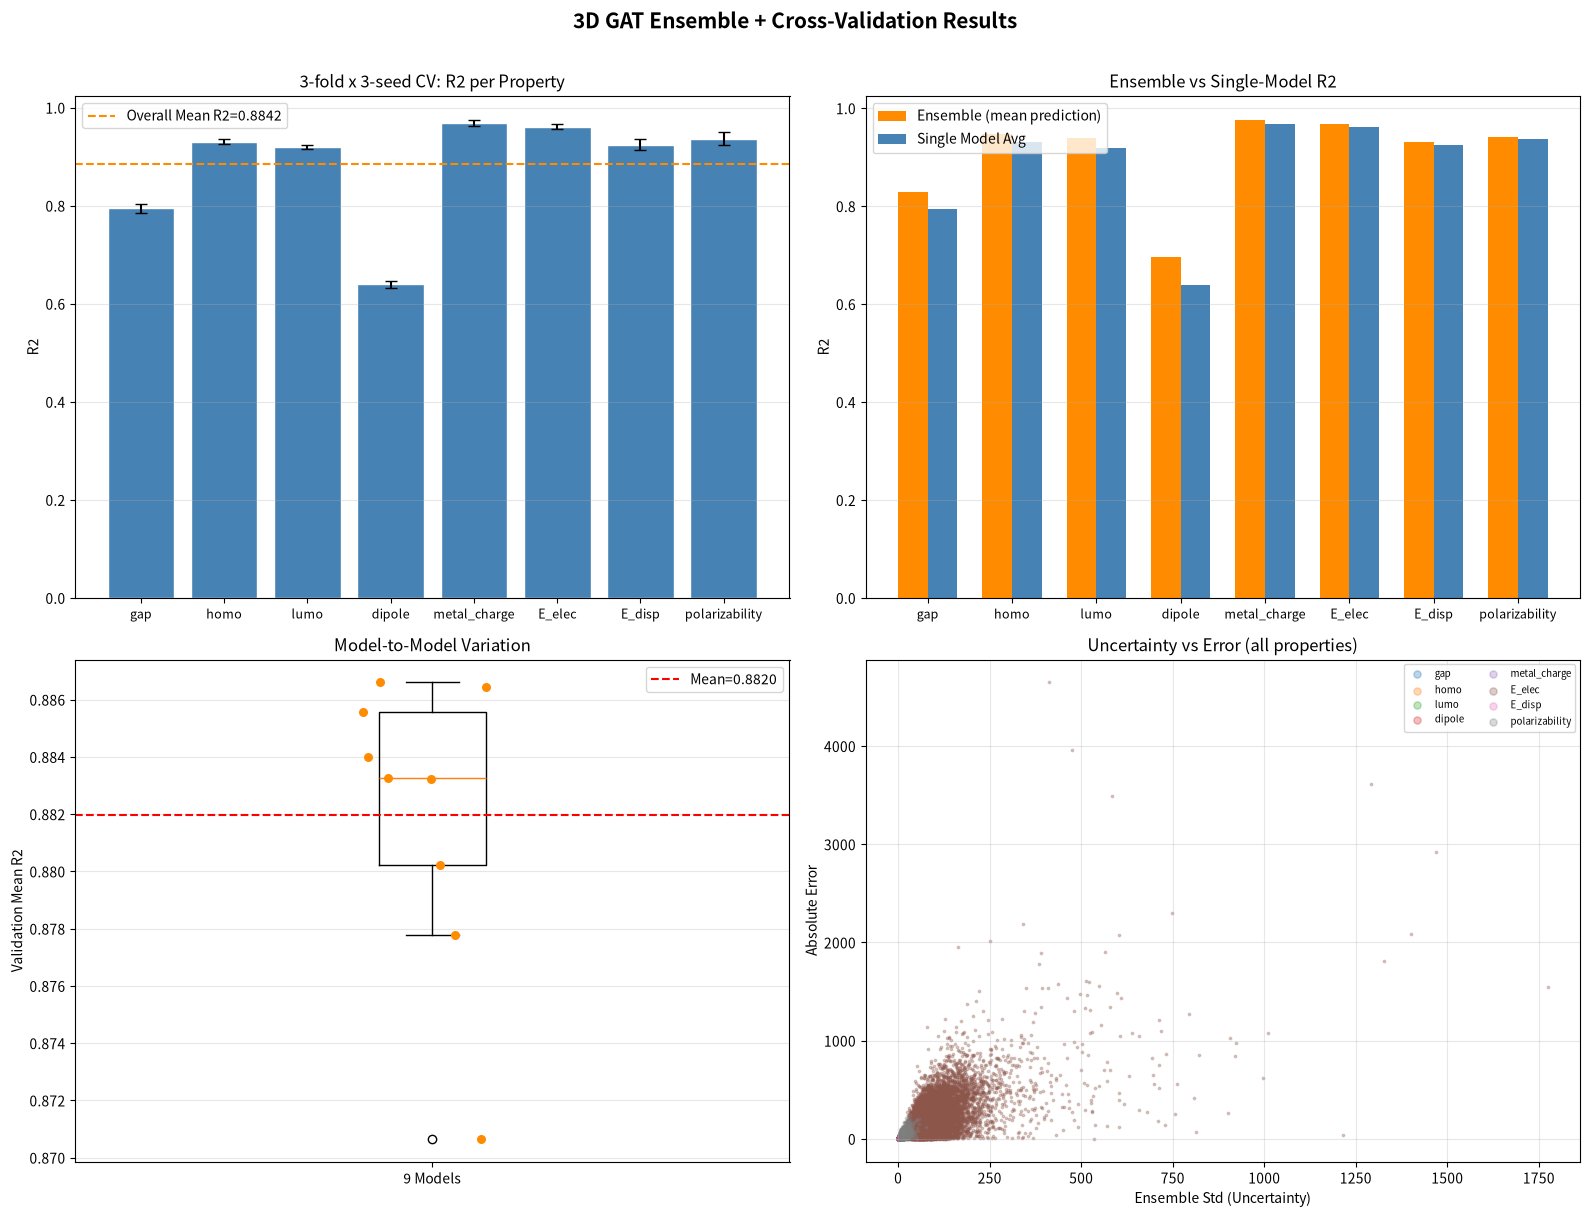

CV Mean R2: 0.8820 +/- 0.0048
Ensemble R2: 0.9030
Single Model R2: 0.8842 +/- 0.0078


In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

ax = axes[0, 0]
x = np.arange(len(targets))
means = ens_df['Mean_R2'].values
stds = ens_df['Std_R2'].values
ax.bar(x, means, yerr=stds, capsize=4, color='steelblue', edgecolor='white')
ax.axhline(y=np.mean(means), color='darkorange', linestyle='--', linewidth=1.5, label=f'Overall Mean R2={np.mean(means):.4f}')
ax.set_xticks(x); ax.set_xticklabels(targets, fontsize=9)
ax.set_ylabel('R2'); ax.set_title(f'3-fold x 3-seed CV: R2 per Property')
ax.legend(); ax.grid(axis='y', alpha=0.3)

ax = axes[0, 1]
x2 = np.arange(len(targets))
w = 0.35
ax.bar(x2 - w/2, ens_df['Ensemble_R2'].values, w, label='Ensemble (mean prediction)', color='darkorange')
ax.bar(x2 + w/2, ens_df['Mean_R2'].values, w, label='Single Model Avg', color='steelblue')
ax.set_xticks(x2); ax.set_xticklabels(targets, fontsize=9)
ax.set_ylabel('R2'); ax.set_title('Ensemble vs Single-Model R2')
ax.legend(); ax.grid(axis='y', alpha=0.3)

ax = axes[1, 0]
val_data = []
for r in results_log:
    if 'val_r2s' in r:
        val_data.append(np.mean(r['val_r2s']))
if len(val_data) > 0:
    ax.boxplot([val_data])
    ax.set_xticklabels(['9 Models'])
    ax.scatter(np.ones(len(val_data)) + np.random.uniform(-0.1, 0.1, len(val_data)),
               val_data, color='darkorange', s=30, zorder=5)
    ax.axhline(y=np.mean(val_data), color='red', linestyle='--', label=f'Mean={np.mean(val_data):.4f}')
ax.set_ylabel('Validation Mean R2'); ax.set_title('Model-to-Model Variation')
ax.legend(); ax.grid(axis='y', alpha=0.3)

ax = axes[1, 1]
for i, prop in enumerate(targets):
    yt = y_test_true[:, i].numpy()
    abs_err = np.abs(ensemble_mean[:, i] - yt)
    ax.scatter(ensemble_std[:, i], abs_err, alpha=0.3, s=3, label=prop)
ax.set_xlabel('Ensemble Std (Uncertainty)'); ax.set_ylabel('Absolute Error')
ax.set_title('Uncertainty vs Error (all properties)')
ax.legend(ncol=2, fontsize=7, markerscale=3); ax.grid(True, alpha=0.3)

plt.suptitle('3D GAT Ensemble + Cross-Validation Results', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figure2_ensemble.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

if len(val_data) > 0:
    print(f'CV Mean R2: {np.mean(val_means):.4f} +/- {np.std(val_means):.4f}')
print(f'Ensemble R2: {ens_df["Ensemble_R2"].mean():.4f}')
print(f'Single Model R2: {ens_df["Mean_R2"].mean():.4f} +/- {ens_df["Std_R2"].mean():.4f}')

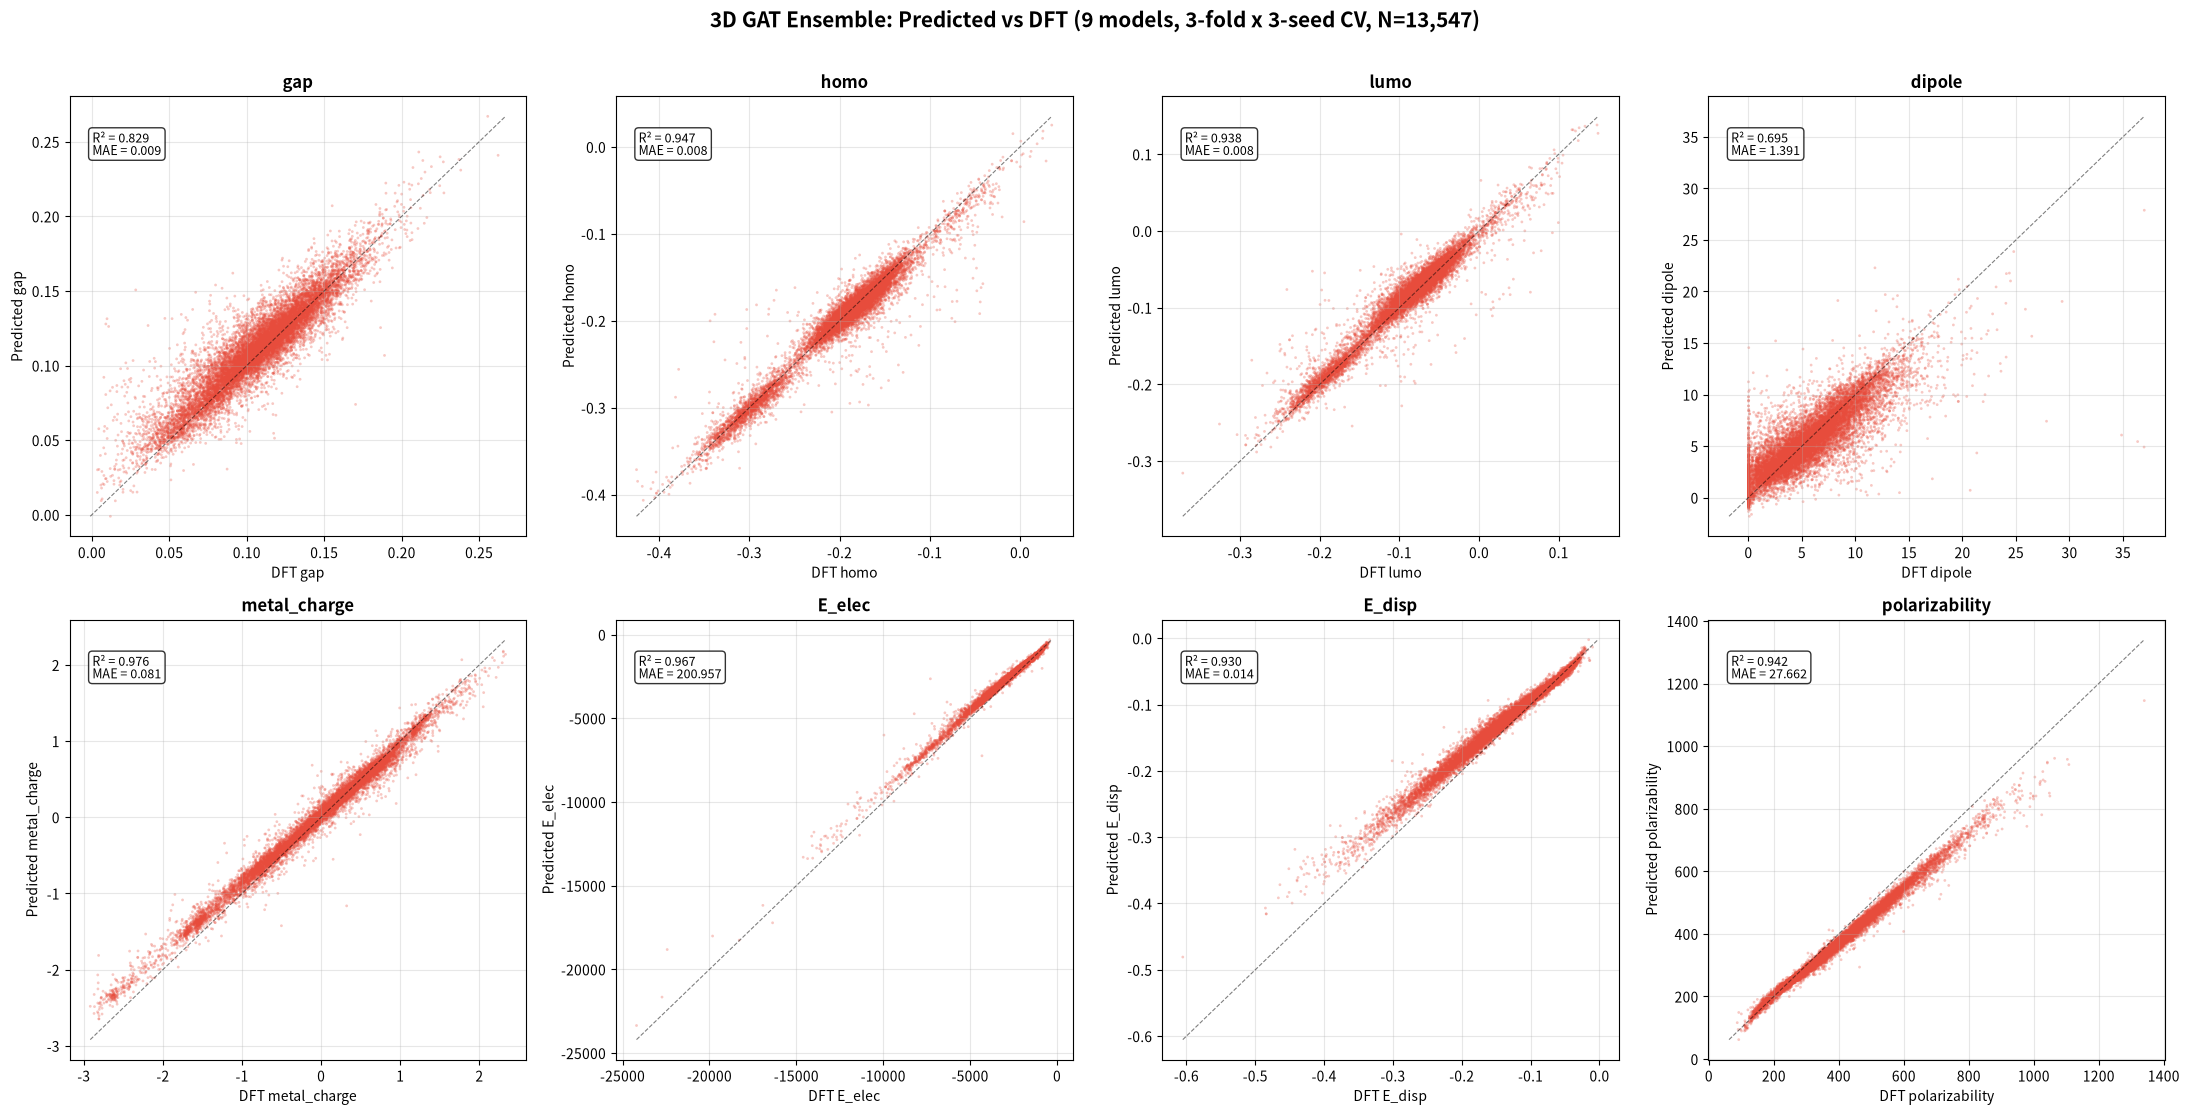

Saved figure2_parity.png


In [9]:
# ===== Figure 2 (main): Predicted vs DFT parity plot (8 properties) =====
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
axes = axes.flatten()

for i, prop in enumerate(targets):
    ax = axes[i]
    yt = y_test_true[:, i].numpy()
    yp = ensemble_mean[:, i]
    r2 = r2_score(yt, yp)
    mae = mean_absolute_error(yt, yp)

    ax.scatter(yt, yp, alpha=0.3, s=4, c='#E74C3C', edgecolors='none')
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, 'k--', lw=0.8, alpha=0.5)

    # Annotate R2 and MAE
    ax.text(0.05, 0.92, f'R² = {r2:.3f}\nMAE = {mae:.3f}',
            transform=ax.transAxes, fontsize=9, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

    ax.set_xlabel(f'DFT {prop}'); ax.set_ylabel(f'Predicted {prop}')
    ax.set_title(f'{prop}', fontweight='bold')
    ax.grid(alpha=0.3)

plt.suptitle('3D GAT Ensemble: Predicted vs DFT (9 models, 3-fold x 3-seed CV, N={:,})'.format(len(te_idx)),
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figure2_parity.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved figure2_parity.png')


## Ensemble + CV 结论### 与 tmGNN-XAI 的对比| 指标 | tmGNN-XAI | 本工作 ||------|:---:|:---:|| CV方案 | 3-repeat × 5-fold (15模型) | 5-fold × 3-seed (9模型) || Ensemble | Top-5 按val loss选 | 全部9模型平均 || 不确定性 | CV (ensemble标准差) | CV (ensemble标准差) || 物理约束 | ✅ HL-Gap = LUMO - HOMO | ❌ 待加入 (1.5) |### 对论文的价值1. **R² ± std 报告**: 回应审稿人R2对可复现性的质疑2. **Ensemble提升**: 量化ensemble相比单模型的增益3. **不确定性估计**: 为后续信任框架(Scenario A/B)提供基础4. **模型稳定性**: std小 → 架构设计合理, 非运气好### 局限- 测试集只有15%，CV只在training+val上做- 9模型比tmGNN-XAI的15模型少，但3-seed已够评估方差